![title](https://ik.imagekit.io/vzr6ryejm/colab/jupyter_notebook-distribuicoes.drawio.png)

# 📗 Entendendo Distribuições de Dados

### 🎯 O que será tratado neste Notebook
- O que é uma **distribuição de dados**
- Os **tipos de distribuição**: normal, assimétrica, uniforme e bimodal
- Como escolher o **gráfico certo** (histograma, linhas, barras, pizza, box plot e dispersão)

### 💡 Dica
Neste notebook cada célula faz **uma coisa só** e cada gráfico mostra **no máximo duas variáveis**.

> ℹ️ Os textos de interpretação foram escritos para a **base padrão** (50 linhas, semente 21). Os números calculados nas células sempre se atualizam; se você gerar outra base, alguns comentários podem precisar de ajuste.

## 🔧 Preparação
Esta primeira célula carrega as ferramentas e os dados. Você só precisa executá-la.

### 📚 Importando as Bibliotecas

In [6]:
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

from google.colab import drive          # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import drive, files   # (files) envia arquivos do seu computador para o Colab

import numpy as np                 # contas matemáticas (ex.: raiz quadrada)
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (10, 6)    # tamanho padrão dos gráficos

### 🔄 Carregando a base de dados

In [7]:
drive.mount("/content/drive")      # vai pedir autorização na primeira vez
pasta_colab = Path("/content/drive/MyDrive/Colab Notebooks") # pasta dos notebooks do Colab no Google Drive
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/estatistica/dados") # pasta onde a base de dados fica guardada no Drive
caminho_do_csv = pasta_dados / "alunos.csv"

# Se o arquivo ainda não existir no Drive, pede o upload e grava na pasta indicada
if not caminho_do_csv.exists():
    pasta_dados.mkdir(parents=True, exist_ok=True)   # cria a pasta "dados" se faltar
    print("Base não encontrada. Selecione o arquivo CSV para enviar:")
    enviados = files.upload()                        # abre o seletor de arquivos
    nome_enviado = next(iter(enviados))              # nome do arquivo escolhido
    shutil.move(nome_enviado, caminho_do_csv)        # move o arquivo enviado para a pasta de dados (alunos.csv)
    print(f"Arquivo salvo em: {caminho_do_csv}")

dados = pd.read_csv(caminho_do_csv)
dados.head()

Mounted at /content/drive


,id_aluno,curso,turno,mes_da_matricula,horas_estudo_semana,horas_sono_noite,numero_de_faltas,nota_final,renda_familiar_mensal,tempo_de_deslocamento_min,nota_diagnostico,aproveitamento_atividades_pct,nivel_engajamento
0,ALU-2664-EN,Saúde,Tarde,Jan,14.5,6.9,2,8.3,26709.31,45,7.5,70.5,Alto
1,ALU-1107-KJ,Direito,Tarde,Jan,15.4,8.2,2,8.5,5607.19,86,8.9,84.5,Alto
2,ALU-8645-CG,Engenharia,Noite,Abr,9.3,7.2,7,3.8,3604.23,24,3.2,57.6,Médio
3,ALU-0836-KV,Engenharia,Noite,Ago,6.1,7.1,4,4.3,2684.80,44,2.9,22.7,Baixo
4,ALU-7042-PH,Saúde,Tarde,Jan,20.2,6.4,1,8.8,2993.52,48,4.8,66.5,Alto


### 📅 Ajustando a Ordem correta dos meses

In [8]:
# Ordem correta dos meses (variável ordinal): sem isso o gráfico de linhas ficaria embaralhado
ordem_dos_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

# Converte a coluna de texto para o tipo Categorical com ordem personalizada (ordered=True)
dados["mes_da_matricula"] = pd.Categorical(dados["mes_da_matricula"], categories=ordem_dos_meses, ordered=True)
dados.head()

,id_aluno,curso,turno,mes_da_matricula,horas_estudo_semana,horas_sono_noite,numero_de_faltas,nota_final,renda_familiar_mensal,tempo_de_deslocamento_min,nota_diagnostico,aproveitamento_atividades_pct,nivel_engajamento
0,ALU-2664-EN,Saúde,Tarde,Jan,14.5,6.9,2,8.3,26709.31,45,7.5,70.5,Alto
1,ALU-1107-KJ,Direito,Tarde,Jan,15.4,8.2,2,8.5,5607.19,86,8.9,84.5,Alto
2,ALU-8645-CG,Engenharia,Noite,Abr,9.3,7.2,7,3.8,3604.23,24,3.2,57.6,Médio
3,ALU-0836-KV,Engenharia,Noite,Ago,6.1,7.1,4,4.3,2684.80,44,2.9,22.7,Baixo
4,ALU-7042-PH,Saúde,Tarde,Jan,20.2,6.4,1,8.8,2993.52,48,4.8,66.5,Alto


### 🔡 Tipos de dados do Pandas

| **Tipo de Dado (Dtype)** | **Descrição**                                                | **Exemplo de Uso**                       |
| ------------------------ | ------------------------------------------------------------ | ---------------------------------------- |
| **`int64`** (ou `int32`) | Números inteiros (positivos, negativos e zero, sem parte decimal). | `10`, `-5`, `1000`                       |
| **`float64`**            | Números de ponto flutuante (números reais com parte decimal). | `10.5`, `-3.14`, `0.001`                 |
| **`object`**             | Usado principalmente para **textos (strings)**, mas também para coleções ou dados mistos (quando há múltiplos tipos na mesma coluna). | `"João"`, `"São Paulo"`, `"2026-11-11"`  |
| **`bool`**               | Valores lógicos booleanos: verdadeiro ou falso.              | `True`, `False`                          |
| **`datetime64[ns]`**     | Datas e horários (timestamps), fundamentais para séries temporais. | `2026-11-11 05:27:00`                    |
| **`category`**           | Dados categóricos que possuem um conjunto fixo e limitado de valores (ex: estados civis, dias da semana). Economiza muita memória e acelera processamentos. | `"Solteiro"`, `"Casado"`, `"Divorciado"` |
| **`timedelta64[ns]`**    | Representa a diferença exata entre duas datas ou horários.   | `5 days`, `2 hours`                      |

In [9]:
dados.dtypes

,0
id_aluno,object
curso,object
turno,object
mes_da_matricula,category
horas_estudo_semana,float64
horas_sono_noite,float64
numero_de_faltas,int64
nota_final,float64
renda_familiar_mensal,float64
tempo_de_deslocamento_min,int64


Observe que a coluna `mes_da_matricula` mudou para category

## 1️⃣ Por que usar gráficos?
Veja a **mesma informação** de duas formas. Primeiro, **números brutos**:

In [10]:
# Tempo (em minutos) que cada aluno leva para chegar à faculdade: só as 10 primeiras linhas
dados[["id_aluno", "tempo_de_deslocamento_min"]].head(10)

,id_aluno,tempo_de_deslocamento_min
0,ALU-2664-EN,45
1,ALU-1107-KJ,86
2,ALU-8645-CG,24
3,ALU-0836-KV,44
4,ALU-7042-PH,48
5,ALU-0495-PP,79
6,ALU-2226-MT,22
7,ALU-9584-SS,60
8,ALU-0060-PR,71
9,ALU-6496-HT,19


Agora, **a coluna inteira** (50 alunos) em um gráfico. Percebeu como ficou mais fácil de entender?

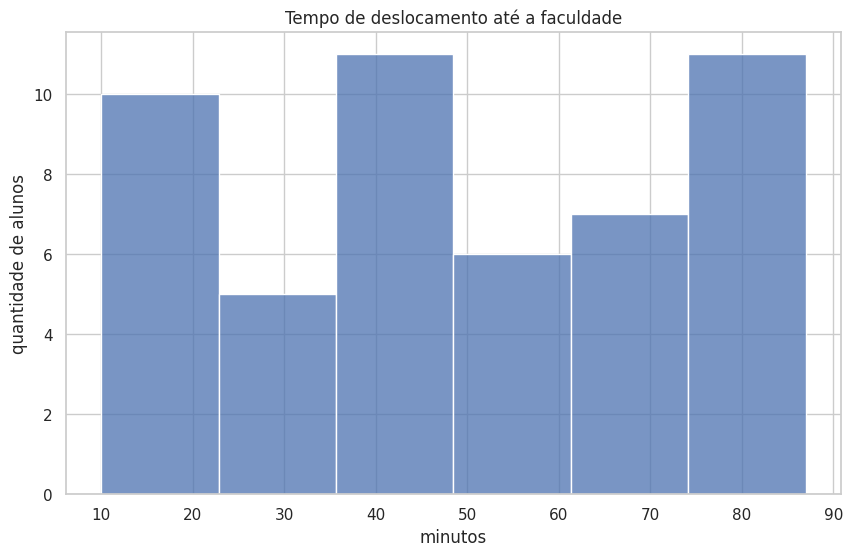

In [11]:
sns.histplot(data=dados, x="tempo_de_deslocamento_min", bins=6)      # histograma
plt.title("Tempo de deslocamento até a faculdade")
plt.xlabel("minutos")
plt.ylabel("quantidade de alunos")
plt.show()

> 💡 Gráficos revelam **padrões** que uma lista de números esconde e ajudam a **decidir** mais rápido.

## 2️⃣ O que é distribuição de dados?
A **distribuição** mostra **como os valores se espalham**: quais aparecem mais, quais aparecem menos e quais são raros. Isso nos ajuda a saber o que é **normal** e o que é **incomum**.

A forma mais direta de descrever uma distribuição é a **tabela de frequências**:

| Sigla | Nome | Como calcular |
|---|---|---|
| **fa** | frequência absoluta | quantas vezes o valor aparece |
| **fr** | frequência relativa | $fr = fa \div n$ (em %: $\times 100$) |
| **fac** | absoluta acumulada | soma das `fa` até aquela linha |
| **frac** | relativa acumulada | soma das `fr` até aquela linha |

### 📶 Tabela de frequências de uma variável QUALITATIVA

In [14]:
# turno

tabela_turno = pd.DataFrame({
  "fa": dados["turno"].value_counts(), # Frequência absoluta - Mostra quantas vezes cada valor aparece
  "fr": (dados["turno"].value_counts(normalize=True) * 100).round(1)  # Frequência relativa - Frequência absoluta dividido pela quantidade de elementos (Em % fazemos * 100)
})

tabela_turno['fac'] = tabela_turno['fa'].cumsum() # Frequência Acumulada - Soma a atual com a anterior

tabela_turno

,fa,fr,fac
turno,,,
Tarde,19,38.0,19
Noite,18,36.0,37
Manhã,13,26.0,50


### 📶 Tabela de frequências de uma variável DISCRETA

### 📶 Tabela de frequências de uma variável CONTÍNUA

Em variáveis **contínuas** (como a nota) os valores são **agrupados em classes** (intervalos). É exatamente isso que o **histograma** desenha. A regra mais simples para o número de classes é $k = \sqrt{n}$.

## Selecionando a coluna `nota_final`

In [15]:
notas = dados["nota_final"]

notas.describe()

,nota_final
count,50.000000
mean,6.088000
std,1.777598
min,3.000000
25%,4.375000
50%,6.250000
75%,7.650000
max,8.900000


### Construíndo a tabela de *frequências*

In [29]:
numero_classes = round(np.sqrt(len(notas)))
print(f"Número de classes: {numero_classes}")

quantidade_por_classe, limites = np.histogram(notas, bins=numero_classes)

print(f'Limite das classes: {limites.round(1).tolist()}')
print(f'Quantidade de alunos por classe: {quantidade_por_classe}\n') # Quantidade de alunos por Intervalo. Ex: Entre 3.0 e 3.8 temos 7 alunos

tabela_notas = pd.DataFrame({
    "classe de notas": [f"{inicio:.1f} a {fim:.1f}" for inicio, fim in zip(limites[:-1], limites[1:])],
    "fa": quantidade_por_classe,
})

tabela_notas["fr (%)"] = (tabela_notas["fa"] / tabela_notas["fa"].sum() * 100).round(1)
tabela_notas["fac"] = tabela_notas["fa"].cumsum()
tabela_notas["frac (%)"] = tabela_notas["fr (%)"].cumsum().round(1)


tabela_notas


Número de classes: 7
Limite das classes: [3.0, 3.8, 4.7, 5.5, 6.4, 7.2, 8.1, 8.9]
Quantidade de alunos por classe: [7 7 6 7 9 5 9]



,classe de notas,fa,fr (%),fac,frac (%)
0,3.0 a 3.8,7,14.0,7,14.0
1,3.8 a 4.7,7,14.0,14,28.0
2,4.7 a 5.5,6,12.0,20,40.0
3,5.5 a 6.4,7,14.0,27,54.0
4,6.4 a 7.2,9,18.0,36,72.0
5,7.2 a 8.1,5,10.0,41,82.0
6,8.1 a 8.9,9,18.0,50,100.0


### Gráfico da Tabela de Frequências

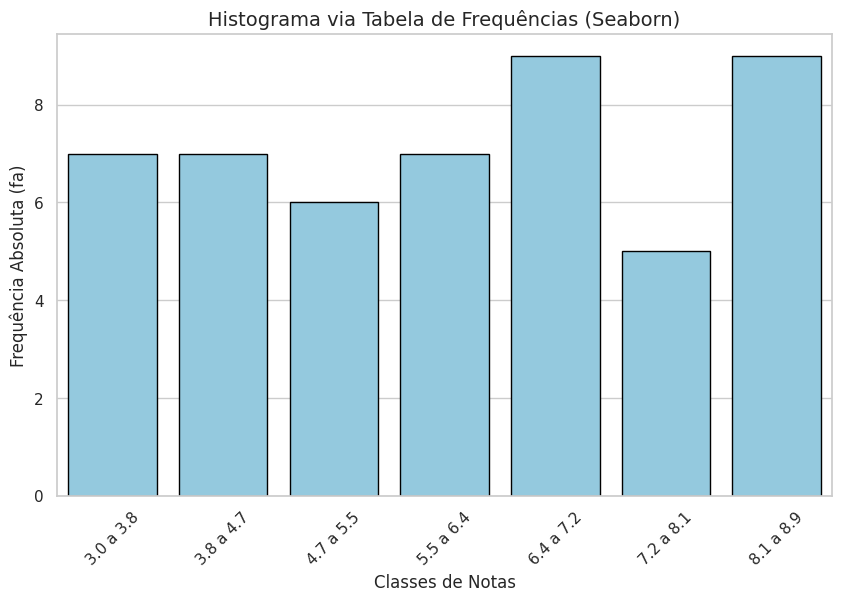

In [30]:
# Usando o DataFrame que você criou
sns.barplot(
    data=tabela_notas,
    x="classe de notas",
    y="fa",
    color="skyblue",
    edgecolor="black"
)

plt.title("Histograma via Tabela de Frequências (Seaborn)", fontsize=14)
plt.xlabel("Classes de Notas", fontsize=12)
plt.ylabel("Frequência Absoluta (fa)", fontsize=12)
plt.xticks(rotation=45) # Rotaciona os nomes dos intervalos para facilitar a leitura

plt.show()


Histogramas não funcionam com Tabelas de Frequências porque ele espera receber os dados brutos, ao invés dos dados agregados.

## 3️⃣ Tipos de distribuição
Existem **quatro formatos** principais. Para reconhecê-los, compare a **média** e a **mediana**:

| Tipo | Como é o gráfico | Média × mediana |
|---|---|---|
| **Normal** | forma de **sino**, simétrica | **iguais** |
| **Assimétrica à direita** | cauda comprida para a **direita** | **média > mediana** |
| **Assimétrica à esquerda** | cauda comprida para a **esquerda** | **média < mediana** |
| **Uniforme** | barras com **alturas parecidas** | sem pico claro |
| **Bimodal** | **dois picos** (dois grupos) | a média cai "no vale" |

Vamos criar uma **função** para desenhar cada histograma sempre do mesmo jeito (assim não repetimos o código).

In [32]:
# Uma função é um "atalho": escrevemos o código uma vez e usamos várias vezes
def desenhar_histograma(coluna, titulo):
    # Barras do histograma + curva suave (kde=True)
    sns.histplot(data=dados, x=coluna, bins=6, kde=True)

    # Linhas da média (vermelha) e da mediana (verde tracejada)
    plt.axvline(dados[coluna].mean(), color="red", linewidth=2, label="média")
    plt.axvline(dados[coluna].median(), color="green", linestyle="--", linewidth=2, label="mediana")

    plt.title(titulo)
    plt.ylabel("quantidade de alunos")
    plt.legend()
    plt.show()

    # skew() mede a assimetria: perto de 0 = simétrica; positivo = cauda à direita; negativo = à esquerda
    print(f"média = {dados[coluna].mean():.1f} | mediana = {dados[coluna].median():.1f} | "
          f"assimetria = {dados[coluna].skew():+.2f}")

### 🔔 Distribuição normal: horas de sono por noite

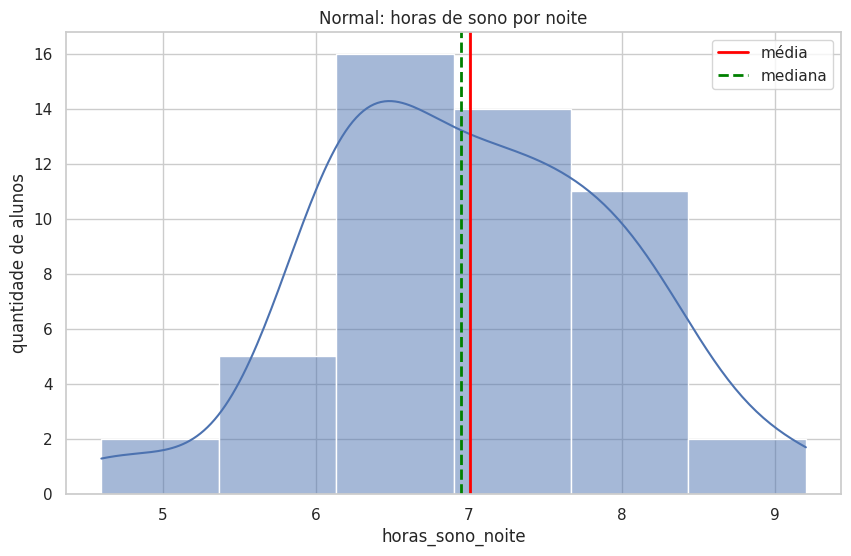

média = 7.0 | mediana = 7.0 | assimetria = -0.02


In [33]:
desenhar_histograma("horas_sono_noite", "Normal: horas de sono por noite")

Forma de **sino**: a maioria dorme perto de 7 horas e poucos dormem muito pouco ou muito. **Média ≈ mediana** e assimetria perto de zero.

### ➡️ Assimétrica à direita: renda familiar

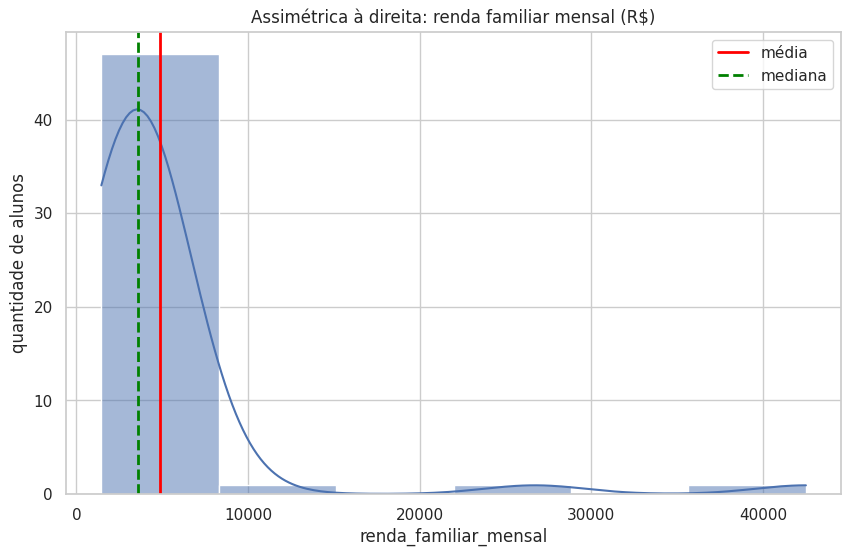

média = 4895.3 | mediana = 3606.1 | assimetria = +5.00


In [34]:
desenhar_histograma("renda_familiar_mensal", "Assimétrica à direita: renda familiar mensal (R$)")

A maioria das famílias está na faixa mais baixa e **poucas têm renda muito alta** (cauda para a direita). A **média é maior que a mediana**, puxada pelos valores altos.

### ⬅️ Assimétrica à esquerda: aproveitamento nas atividades

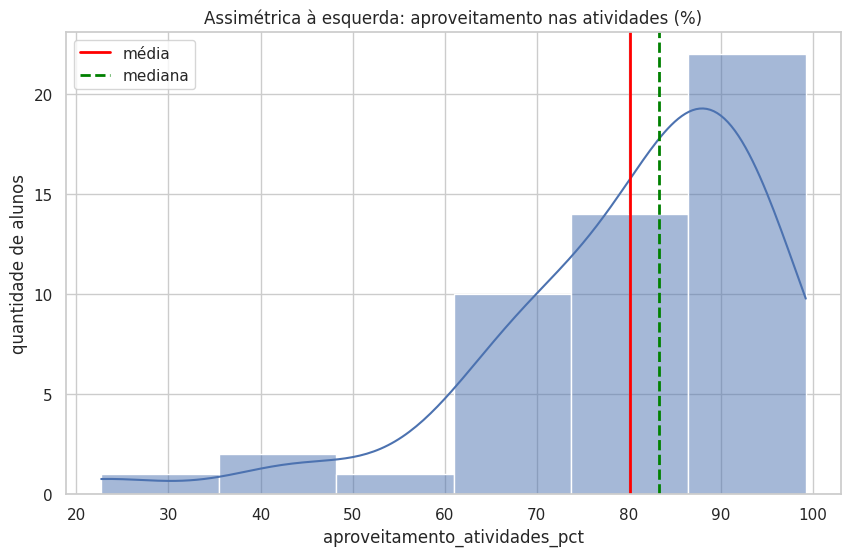

média = 80.2 | mediana = 83.3 | assimetria = -1.63


In [35]:
desenhar_histograma("aproveitamento_atividades_pct", "Assimétrica à esquerda: aproveitamento nas atividades (%)")

A maioria dos alunos tem aproveitamento **alto** e **poucos têm aproveitamento muito baixo** (cauda para a esquerda). A **média é menor que a mediana**.

### ▬ Uniforme: tempo de deslocamento

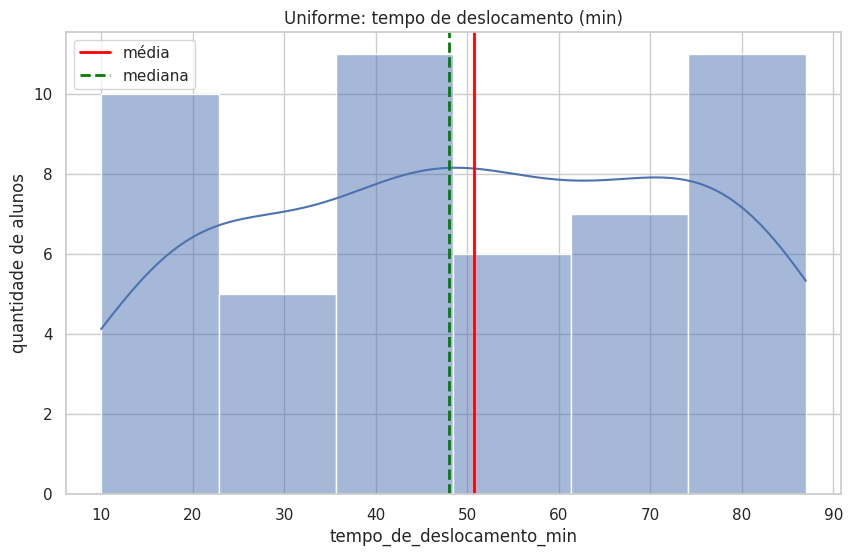

média = 50.7 | mediana = 48.0 | assimetria = -0.07


In [36]:
desenhar_histograma("tempo_de_deslocamento_min", "Uniforme: tempo de deslocamento (min)")

As barras têm **alturas parecidas**: qualquer tempo entre 10 e 90 minutos é **igualmente provável**.

### ⛰️⛰️ Bimodal: nota do teste diagnóstico

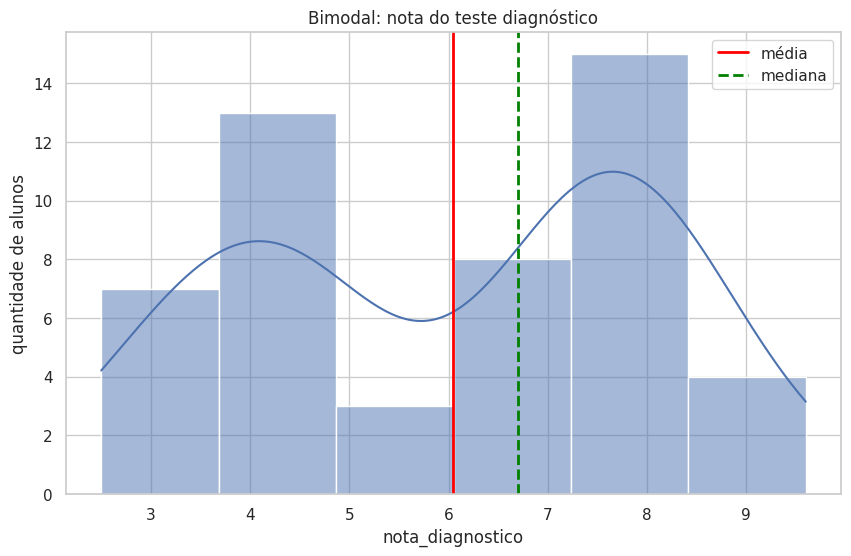

média = 6.0 | mediana = 6.7 | assimetria = -0.18


In [37]:
desenhar_histograma("nota_diagnostico", "Bimodal: nota do teste diagnóstico")

**Dois picos**: existem **dois grupos** (quem chegou com dificuldade e quem chegou bem preparado). Repare que a **média cai no "vale"** entre os picos e não representa nenhum dos grupos.

> ⚠️ A assimetria **não detecta** distribuições uniformes ou bimodais. Para elas é preciso **olhar o histograma**.

### ✍️ Prática: identifique a distribuição
Olhe o histograma e diga: é **normal** (simétrica) ou **assimétrica** (para qual lado)?

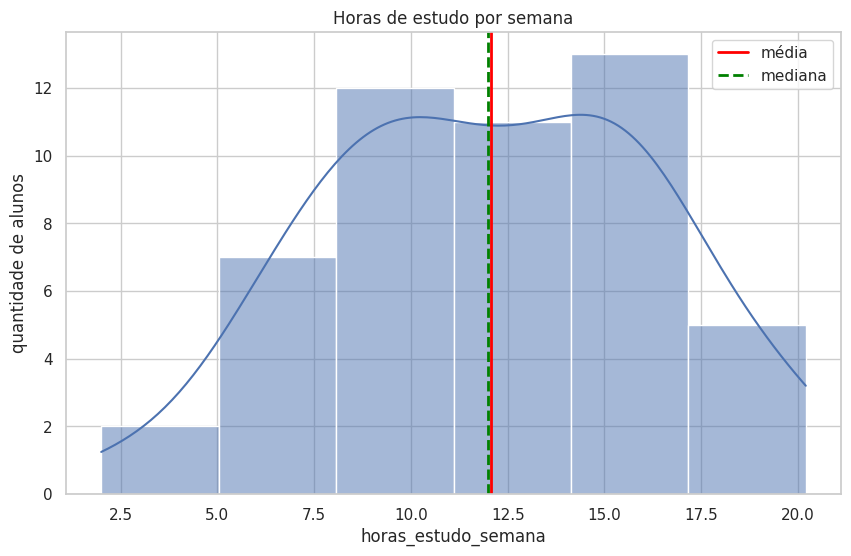

média = 12.1 | mediana = 12.0 | assimetria = -0.10


In [38]:
desenhar_histograma("horas_estudo_semana", "Horas de estudo por semana")

Sua Resposta...

In [ ]:
desenhar_histograma("numero_de_faltas", "Número de faltas")

Sua Resposta...

## 4️⃣ Representações gráficas
Ferramentas como Python, Excel e Power BI desenham o gráfico, mas **você precisa escolher o gráfico certo**. Para isso, pergunte:
1. **Quantas variáveis** vou mostrar?
2. **Quantos pontos de dados** existem?
3. Vou olhar **ao longo do tempo** ou **comparar** valores?

| Gráfico | Para que serve | Exemplo |
|---|---|---|
| **Histograma** | formato da distribuição de uma variável numérica | distribuição das notas |
| **Linhas** | mudanças **ao longo do tempo** | matrículas por mês |
| **Barras / colunas** | **comparar categorias** | nota média por curso |
| **Pizza** | **proporções** de um todo (poucas fatias) | alunos por turno |
| **Box plot** | mediana, quartis e **outliers** | notas por curso |
| **Dispersão** | **relação entre duas variáveis** | horas de estudo × nota |

### 📊 Histograma

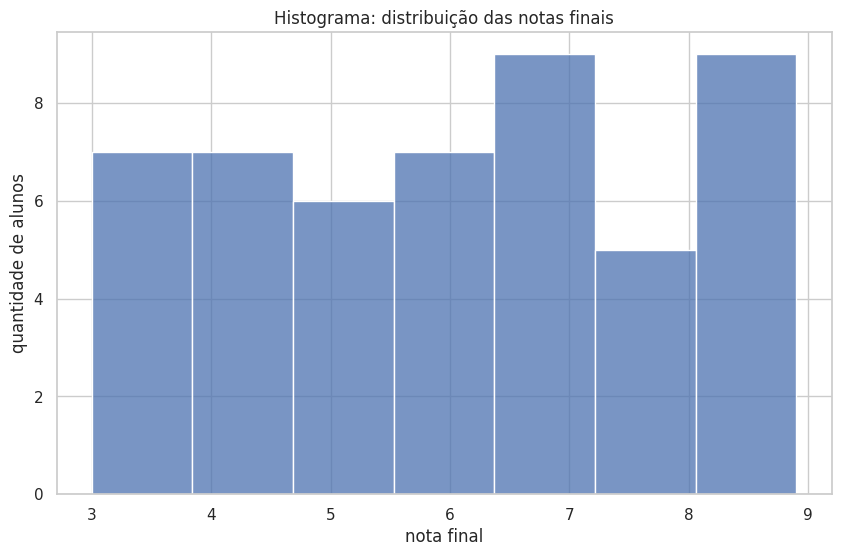

In [39]:
sns.histplot(data=dados, x="nota_final", bins=7)    # bins = número de barras (classes)
plt.title("Histograma: distribuição das notas finais")
plt.xlabel("nota final")
plt.ylabel("quantidade de alunos")
plt.show()

### 📈 Gráfico de linhas (ao longo do tempo)

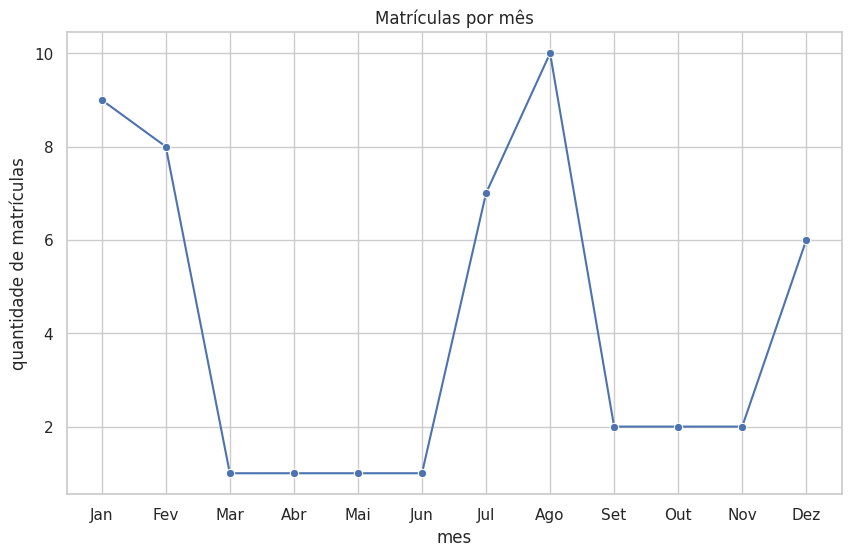

In [40]:
# Gerando um novo DataFrame contendo os meses ordenados e a número de matriculados em cada mês (contagem)
matriculas_por_mes = dados["mes_da_matricula"].value_counts().reindex(ordem_dos_meses).reset_index()
matriculas_por_mes.columns = ["mes", "matriculas"] # Muda o nome das colunas
matriculas_por_mes["mes"] = matriculas_por_mes["mes"].astype(str) # Conversão de dados category -> string

sns.lineplot(data=matriculas_por_mes, x="mes", y="matriculas", marker="o", sort=False)   # sort=False mantém a ordem dos meses
plt.title("Matrículas por mês")
plt.ylabel("quantidade de matrículas")
plt.show()

Há **picos no início de cada semestre** (janeiro/fevereiro e julho/agosto).

### 🏛️ Colunas e barras (comparando categorias)

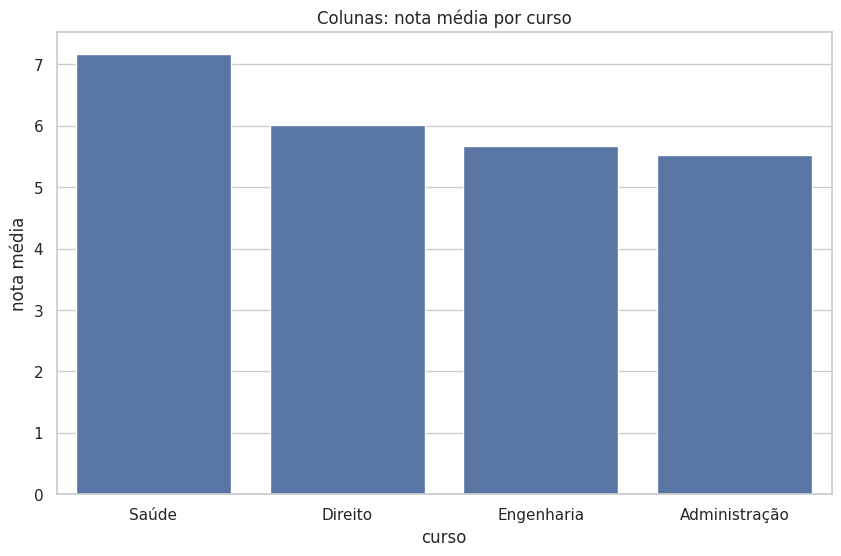

In [41]:
# Colunas (vertical): nota média por curso
sns.barplot(data=dados, x="curso", y="nota_final", errorbar=None)
plt.title("Colunas: nota média por curso")
plt.ylabel("nota média")
plt.show()

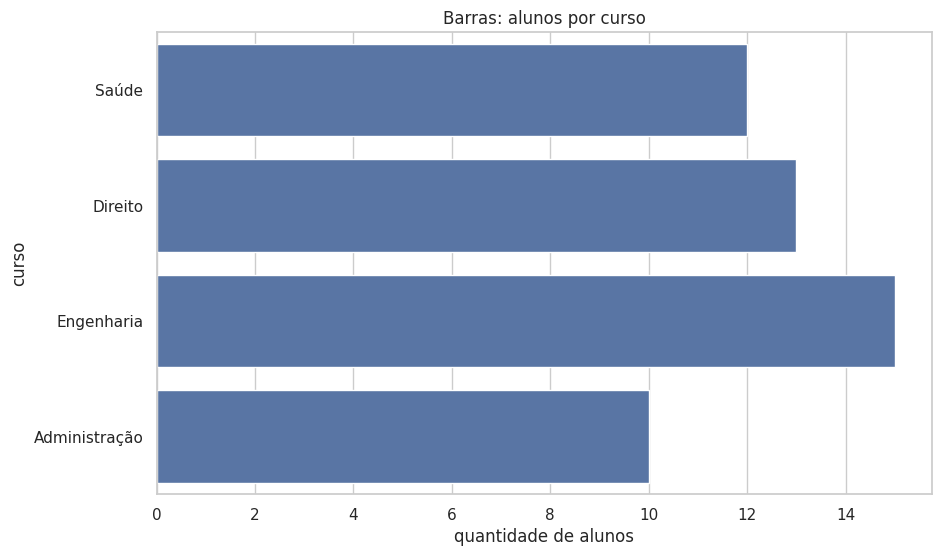

In [42]:
# Barras (horizontal): quantidade de alunos por curso
sns.countplot(data=dados, y="curso")      # y= coloca as categorias no eixo vertical
plt.title("Barras: alunos por curso")
plt.xlabel("quantidade de alunos")
plt.show()

### 🥧 Pizza (proporções, poucas fatias)
O Seaborn não tem gráfico de pizza, então usamos o `plt.pie` do Matplotlib com as cores do Seaborn.

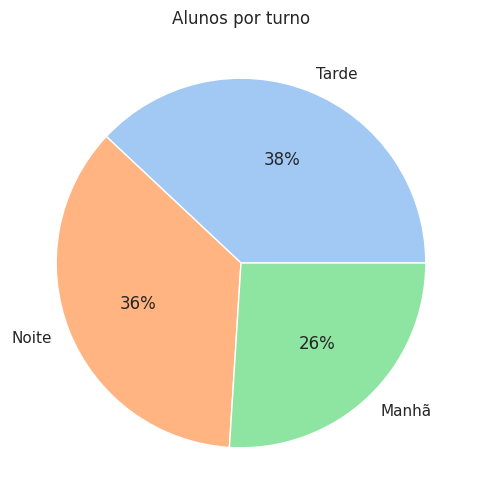

In [43]:
alunos_por_turno = dados["turno"].value_counts()

plt.pie(alunos_por_turno, labels=alunos_por_turno.index, autopct="%.0f%%",   # autopct mostra a porcentagem
        colors=sns.color_palette("pastel"))
plt.title("Alunos por turno")
plt.show()

### 📦 Box plot (mediana, quartis e outliers)
**Como ler:** a **caixa** vai de Q1 a Q3 (50% do meio) · a **linha** dentro é a **mediana** · os "bigodes" mostram o restante dos dados · **pontinhos isolados** são **outliers**.

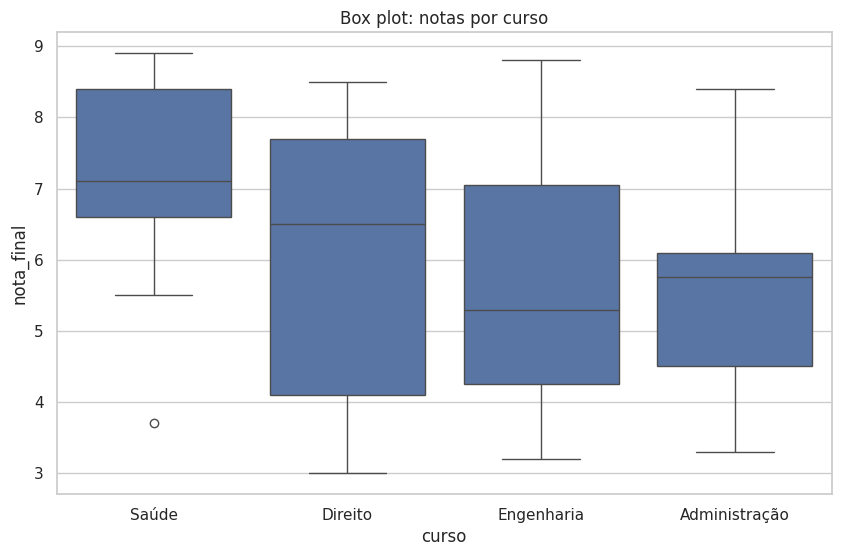

In [44]:
sns.boxplot(data=dados, x="curso", y="nota_final")      # um box plot para cada curso
plt.title("Box plot: notas por curso")
plt.show()

#### Como saber se um valor é outlier?
Usamos a **regra de Tukey** (a mesma do box plot), que usa o IQR que você viu na sessão anterior:

$$LI = Q_1 - 1{,}5 \times IQR \qquad\qquad LS = Q_3 + 1{,}5 \times IQR$$

Valores **abaixo de LI** ou **acima de LS** são outliers. ❗ Outlier **não é sinônimo de erro**: investigue antes de remover.

In [ ]:
renda = dados["renda_familiar_mensal"]

q1 = renda.quantile(0.25)
q3 = renda.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
print(f"Limites: de {limite_inferior:.0f} a {limite_superior:.0f}")

# Selecionando quem está fora dos limites
outliers = renda[(renda < limite_inferior) | (renda > limite_superior)]
print(f"{len(outliers)} outliers na renda:", sorted(outliers.round(0).tolist()))

In [ ]:
sns.boxplot(x=dados["renda_familiar_mensal"])           # os pontinhos à direita são os outliers
plt.title("Box plot da renda familiar mensal (R$)")
plt.show()

### ⚪ Diagrama de dispersão (relação entre duas variáveis)
Cada ponto é **um aluno**. A posição mostra o valor das duas variáveis ao mesmo tempo.

In [ ]:
sns.scatterplot(data=dados, x="horas_estudo_semana", y="nota_final")
plt.title("Dispersão: horas de estudo x nota")
plt.show()

### 📈Reta de Tendência

Uma reta de tendência (ou linha de tendência) é uma linha reta desenhada em um gráfico que resume a direção geral que os dados estão seguindo ao longo do tempo ou de uma sequência.

Em vez de focar nos altos e baixos de cada ponto isolado, a reta mostra o comportamento macro (geral) da informação, respondendo rapidamente se os dados estão crescendo (tendência de alta), caindo (tendência de baixa) ou se mantendo estáveis, mesmo que haja oscilações no meio do caminho.

In [ ]:
# regplot é o scatter com uma reta de tendência (mostra a direção da relação)
sns.regplot(data=dados, x="horas_estudo_semana", y="nota_final", ci=None, line_kws={"color": "red"})
plt.title("Dispersão com reta de tendência")
plt.show()

Os pontos sobem da esquerda para a direita: **quem estuda mais tende a tirar nota maior**. Na próxima sessão vamos **medir** essa relação.

## 5️⃣ Prática: analisando gráficos
Para cada gráfico, responda: **(a)** que tipo de gráfico é? **(b)** o que ele mostra?

### Desafio 1

In [ ]:
sns.histplot(data=dados, x="aproveitamento_atividades_pct", bins=6, kde=True)
plt.title("Desafio 1")
plt.ylabel("quantidade de alunos")
plt.show()

Sua Resposta...

### Desafio 2

In [ ]:
sns.barplot(data=dados, x="turno", y="horas_estudo_semana", errorbar=None)
plt.title("Desafio 2")
plt.ylabel("horas de estudo por semana (média)")
plt.show()

Sua Resposta...

### Desafio 3

In [ ]:
sns.scatterplot(data=dados, x="numero_de_faltas", y="nota_final")
plt.title("Desafio 3")
plt.show()

Sua Resposta...

## ✅ Resumo da sessão
- A **distribuição** mostra como os dados se espalham.
- Quatro formatos: **normal**, **assimétrica**, **uniforme** e **bimodal**. Compare média e mediana e **sempre olhe o histograma**.
- Cada gráfico responde a uma pergunta: **histograma** (formato), **linhas** (tempo), **barras** (comparar categorias), **pizza** (proporções), **box plot** (quartis e outliers), **dispersão** (relação entre duas variáveis).